# 16 — Signal-consistency vetoes and a combined ranking statistic for the bank

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 18 and 39. (i) Adds to the sine-Gaussian bank an **Allen χ² test** (the best template is split into 8 frequency bands of equal power; a real signal distributes its SNR as the template does, a glitch does not) and the **re-weighted "new SNR"**. (ii) Builds a **combined ranking statistic**: a logistic regression and a gradient-boosted classifier on (ρ², χ², new SNR, max|v|, window kurtosis, best-template f₀ and Q), trained on the *training* background and training injections only. All statistics are compared on the *test* injections with thresholds from the *validation* background (convention of notebook 12), mean ρ₅₀ over sine-Gaussian, pulse and chirp at FAP 10⁻² and 10⁻³, bootstrap errors, and against the CNN of notebook 07.

**What it does not do.** The χ² is computed for the sine-Gaussian bank only (not for the IMR bank or the Bayesian cube); the classifiers are small and not tuned; the ranking statistic learns the *training injection prior* (SNR 3–14, the three morphologies) and the glitch population of the training chunks, so its efficiency is for that prior.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import gwosc_tools as g
g.style()
rng = np.random.default_rng(16)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
B160 = {i: g.SGBank(CH[i]["S1"]) for i in CH}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1 = {sp: np.stack([CH[i]["S1"] for i in ID[sp]]) for sp in V}
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 300; P = 8

## 1. Features of every window

In [2]:
def features(v, cid, scan=None):
    sc = scan if scan is not None else g.scan_mixed(v, cid, B160)
    X = g.to_bins(v); chi = np.zeros(len(v))
    for c in np.unique(cid):
        m = cid == c; idx = g.template_index(B160[c], sc["f0"][m], sc["Q"][m])
        chi[m] = g.allen_chi2(B160[c], X[m], sc["tau"][m], idx, p=P)
    rho2 = np.asarray(sc["rho2"]); nsnr = g.new_snr(rho2, chi)
    return dict(rho2=rho2, chi2=chi, nsnr2=nsnr ** 2, vmax=np.abs(v).max(1), kurt=(v ** 4).mean(1) / (v ** 2).mean(1) ** 2,
                lf0=np.log(sc["f0"]), Q=np.asarray(sc["Q"]))
def cached_scan(name):
    d = np.load(os.path.join(g.CACHE, f"scan03_{name}.npz")); return {k: d[k] for k in d.files}
fn = os.path.join(g.CACHE, "stats16.pkl")
if os.path.exists(fn):
    F = pickle.load(open(fn, "rb"))
else:
    t0_ = time.time(); F = {"train_bkg": features(V["train"], ID["train"], cached_scan("train")), "val_bkg": features(V["val"], ID["val"], cached_scan("val"))}
    kinds = rng.choice(g.MORPHS, 6000); snr = rng.uniform(3, 14, 6000); idx = rng.choice(len(V["train"]), 6000)
    ser = np.empty((6000, g.NWIN), np.float32)
    for k in g.MORPHS:
        m = kinds == k; ser[m] = g.inject(V["train"][idx[m]], k, snr[m], rng, S1["train"][idx[m]])[0]
    F["train_inj"] = features(ser, ID["train"][idx])
    for kind in g.MORPHS:
        for s in SNRS:
            i = rng.choice(len(V["test"]), NINJ, replace=False)
            F[(kind, s)] = features(g.inject(V["test"][i], kind, float(s), rng, S1["test"][i])[0], ID["test"][i])
    pickle.dump(F, open(fn, "wb")); print("features: %.0f s" % (time.time() - t0_))
print(len(F), "sets; median reduced chi2 of train noise %.2f, of train injections %.2f" % (np.median(F["train_bkg"]["chi2"]), np.median(F["train_inj"]["chi2"])))

features: 42 s
36 sets; median reduced chi2 of train noise 0.79, of train injections 1.12


## 2. Combined ranking statistics (trained on the training chunks only)

In [3]:
COLS = ["rho2", "chi2", "nsnr2", "vmax", "kurt", "lf0", "Q"]
def mat(d, cols=COLS): return np.column_stack([np.log(d[c]) if c in ("rho2", "chi2", "nsnr2") else d[c] for c in cols])
X = np.vstack([mat(F["train_bkg"]), mat(F["train_inj"])]); y = np.r_[np.zeros(len(F["train_bkg"]["rho2"])), np.ones(len(F["train_inj"]["rho2"]))]
w = np.where(y == 0, 0.5 / (y == 0).sum(), 0.5 / (y == 1).sum()) * len(y)
LR = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(X, y, logisticregression__sample_weight=w)
GB = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, max_iter=200, random_state=0).fit(X, y, sample_weight=w)
STAT = {"bank ρ² (reference)": lambda d: d["rho2"], "χ² veto (c ≤ 3)": lambda d: np.where(d["chi2"] > 3, 0.0, d["rho2"]), "new SNR²": lambda d: d["nsnr2"],
        "logistic regression": lambda d: LR.decision_function(mat(d)), "gradient boosting": lambda d: GB.decision_function(mat(d))}
print("logistic coefficients (standardised):", dict(zip(COLS, np.round(LR[-1].coef_[0], 2))))

logistic coefficients (standardised): {'rho2': np.float64(1.43), 'chi2': np.float64(0.23), 'nsnr2': np.float64(1.83), 'vmax': np.float64(-0.92), 'kurt': np.float64(0.09), 'lf0': np.float64(-0.53), 'Q': np.float64(0.11)}


## 3. Efficiency: thresholds on the validation background, injections on the test chunks

In [4]:
rows = []
for lab, f in STAT.items():
    for far in (1e-2, 1e-3):
        for kind in g.MORPHS:
            p, b = g.bootstrap_rho(f(F["val_bkg"]), [f(F[(kind, s)]) for s in SNRS], SNRS, far, B=200, seed=7)
            rows.append(dict(stat=lab, FAP=far, morph=kind, rho50=p[0], err=(g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2))
R = pd.DataFrame(rows)
T = R.pivot_table(index="stat", columns=["FAP", "morph"], values="rho50"); T[("mean", 1e-2)] = T[1e-2].mean(axis=1); T[("mean", 1e-3)] = T[1e-3].mean(axis=1)
T.round(2)

FAP                 0.001              0.01              mean      
morph               chirp pulse    sg chirp pulse    sg  0.01 0.001
stat                                                               
bank ρ² (reference)  9.11  7.32  6.85  6.37  5.20  4.95  5.51  7.76
gradient boosting    7.24  6.00  5.76  6.05  5.08  5.02  5.38  6.34
logistic regression  7.52  6.00  5.86  6.29  5.23  5.12  5.54  6.46
new SNR²             8.23  6.19  5.74  6.69  5.24  4.97  5.63  6.72
χ² veto (c ≤ 3)      7.41  5.98  5.67  6.30  5.13  4.88  5.44  6.35

CNN fresh (nb07): mean rho50 FAP 1e-2 = 4.57, 1e-3 = 5.66


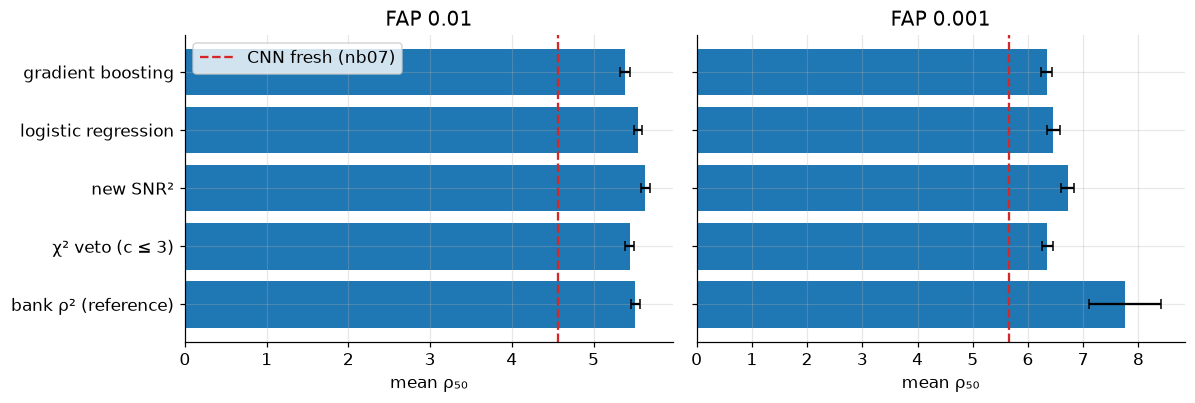

In [5]:
# the CNN of notebook 07 (fresh injections, seed 0) on its own test injections, for scale
import json
d7 = [r for r in g.load_json("07_summary.json")["detection"] if r["model"] == "cnn_fresh s0"]
print("CNN fresh (nb07): mean rho50 FAP 1e-2 = %.2f, 1e-3 = %.2f" % tuple(np.mean([r["rho50"] for r in d7 if r["FAP"] == f]) for f in (1e-2, 1e-3)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, far in zip(ax, (1e-2, 1e-3)):
    m = R[R.FAP == far].groupby("stat", sort=False).agg(rho50=("rho50", "mean"), err=("err", lambda e: float(np.sqrt((e ** 2).sum()) / 3)))
    a.barh(range(len(m)), m.rho50, xerr=m.err, color=g.COLORS["freq"], capsize=3); a.set_yticks(range(len(m))); a.set_yticklabels(m.index); a.invert_yaxis()
    a.axvline(np.mean([r["rho50"] for r in d7 if r["FAP"] == far]), color=g.COLORS["bayes"], ls="--", label="CNN fresh (nb07)"); a.set_title(f"FAP {far:g}"); a.set_xlabel("mean ρ₅₀")
ax[0].legend(); fig.tight_layout(); g.savefig(fig, "fig16_ranking"); plt.show()
g.save_json(dict(rows=R.to_dict("records"), columns=COLS, logistic_coef=dict(zip(COLS, [float(x) for x in LR[-1].coef_[0]]))), "16_summary.json")

## Output and next step

`results/16_summary.json`, `figures/fig16_ranking`. Next: hard-negative mining and glitch classification (extensions 29 and 24).